In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os
import sys

PROJECT    = '/content/drive/MyDrive/Colab Notebooks/ingredient_model'
IMAGE_ROOT = '/content/drive/MyDrive/Colab Notebooks/image_ingredient_dataset'
DATA_DIR   = '/content/data_prepared'
COMPARE_DIR = f'{PROJECT}/runs/model_final'
FINAL_DIR = COMPARE_DIR
os.chdir(PROJECT)
print(os.listdir(PROJECT))
!nvidia-smi -L

['classes_set1.json', 'labels_final_set2_1584.json', 'labels_final_set1_1669.json', 'runs', 'labels_final_set1_1669_fixed.json', 'labels_final_set2_1584_fixed.json']
GPU 0: Tesla T4 (UUID: GPU-0df29211-7d4b-35d7-b6d0-7d7b66cb9897)


In [6]:
import json
from pathlib import Path
from collections import defaultdict

image_root = Path(IMAGE_ROOT)
label_files = ["labels_final_set1_1669.json", "labels_final_set2_1584.json"]

key = lambda p: Path(p).stem.lower().replace(" ", "")
index = defaultdict(list)
for p in image_root.rglob("*"):
    if p.is_file():
        index[key(p)].append(p.relative_to(image_root).as_posix())

for f in label_files:
    data = json.load(open(f, encoding="utf-8"))
    fixed, dropped = [], []

    for row in data:
        img = row["image"]
        if (image_root / img).exists():
            fixed.append(row)
            continue

        found = index.get(key(img), [])
        if len(found) != 1:          # ไม่เจอ หรือเจอหลายไฟล์ → ตัดทิ้ง
            dropped.append(img)
            continue

        new = found[0]
        old_folder = Path(img).parent.name
        new_folder = Path(new).parent.name
        row["image"] = new
        fixed.append(row)

        if old_folder != new_folder:  # ย้ายโฟลเดอร์ → ต้องเช็ค label
            on = [k for k, v in row["labels"].items() if v]
            print(f"⚠️ เช็ค label: {new}\n   (เดิมอยู่ใน {old_folder}) labels = {on}")

    out = f.replace(".json", "_fixed.json")
    json.dump(fixed, open(out, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    print(f"{f}: {len(data)} → {len(fixed)} แถว (ตัดทิ้ง {dropped}) → {out}\n")

labels_final_set1_1669.json: 1669 → 1669 แถว (ตัดทิ้ง []) → labels_final_set1_1669_fixed.json

⚠️ เช็ค label: Set 2/panang/panangbeef/panangbeef(110).jpg
   (เดิมอยู่ใน panangchicken) labels = ['chicken', 'chili', 'kaffir_lime_leaf', 'green_eggplant']
⚠️ เช็ค label: Set 2/tom yum/tom yum pla/tom yum pla (6).jpg
   (เดิมอยู่ใน tom yum kung nam sai) labels = ['fish', 'chili', 'coriander', 'kaffir_lime_leaf']
⚠️ เช็ค label: Set 2/tom yum/tom yum pla/tom yum pla (7).jpg
   (เดิมอยู่ใน tom yum kung nam sai) labels = ['fish', 'chili', 'lime', 'kaffir_lime_leaf']
⚠️ เช็ค label: Set 2/tom yum/tom yum pla/tom yum pla (8).jpg
   (เดิมอยู่ใน tom yum kung nam sai) labels = ['fish', 'chili', 'tomato', 'coriander', 'kaffir_lime_leaf']
⚠️ เช็ค label: Set 2/tom yum/tom yum pla/tom yum pla (9).jpg
   (เดิมอยู่ใน tom yum kung nam sai) labels = ['fish', 'chili', 'mushroom', 'coriander', 'kaffir_lime_leaf']
⚠️ เช็ค label: Set 2/tom yum/tom yum pla/tom yum pla (10).jpg
   (เดิมอยู่ใน tom yum kung nam sai) 

In [14]:
BACKBONE = "efficientnetb0"
IMG_SIZE = 224
BATCH = 32
EPOCHS_HEAD = 10
EPOCHS_FT = 40
PATIENCE = 8
SEED =42

In [15]:
import csv
import hashlib
import json
import random
from collections import defaultdict
from pathlib import Path

from PIL import Image, ImageOps

# อ่านไฟล์ JSON
def read_json(path):
    with open(path, "r", encoding="utf-8") as file:
        return json.load(file)


# แยกชื่อเมนูและเมนูย่อย
def get_menu(image_path):
    parts = image_path.replace("\\", "/").split("/")

    if len(parts) >= 3:
        menu = parts[1]
        variant = parts[-2]

    else:
        menu = "unknown"
        variant = "unknown"

    return menu, variant


# คำนวณ Hash ของรูปภาพ
def get_hash(image):
    image = image.convert("L")
    image = image.resize((17, 16), Image.LANCZOS)

    pixels = list(image.getdata())
    image_hash = 0

    for row in range(16):
        for col in range(16):
            left = pixels[row * 17 + col]
            right = pixels[row * 17 + col + 1]

            image_hash = image_hash << 1

            if left > right:
                image_hash += 1

    return image_hash


# รวมไฟล์ Label
def combine_labels(label_files, all_classes):
    images = {}

    for file_index, label_file in enumerate(label_files):
        data = read_json(label_file)

        for row in data:
            image_path = row["image"]

            if image_path not in images:
                images[image_path] = []

            images[image_path].append(
                (file_index, row["id"], row["labels"])
            )

    rows = []

    for image_path, items in images.items():
        items.sort(key=lambda item: (item[0], item[1]))

        # ใช้ Label จากอันล่าสุด
        labels = items[-1][2]

        new_row = {
            "image": image_path,
            "labels": {}
        }

        for name in all_classes:
            new_row["labels"][name] = int(labels.get(name, 0))

        rows.append(new_row)

    return rows


# prepare image

import time

def prepare_images(rows, image_root, output):
    cache_dir = output / "cache"
    cache_dir.mkdir(parents=True, exist_ok=True)

    usable_images = []
    missing_count = 0
    start_time = time.time()

    for i, row in enumerate(rows, start=1):
        source = image_root / row["image"]

        file_name = hashlib.sha1(
            row["image"].encode()
        ).hexdigest()[:16] + ".jpg"

        target = cache_dir / file_name

        try:
            if target.exists():
                with Image.open(target) as image:
                    image_hash = get_hash(image)

            else:
                with Image.open(source) as image:
                    image = ImageOps.exif_transpose(image)
                    image = image.convert("RGB")
                    image.thumbnail((640, 640), Image.LANCZOS)
                    image.save(target, "JPEG", quality=92)

                    # คำนวณ Hash จากรูปที่เปิดอยู่แล้ว
                    image_hash = get_hash(image)

            row["hash"] = image_hash
            row["cache_path"] = str(target.relative_to(output))
            row["dish"], row["variant"] = get_menu(row["image"])

            usable_images.append(row)

        except Exception as e:
            missing_count += 1
            print(f"ข้ามรูป: {row['image']} ({e})")

        # แสดงความคืบหน้าทุก 100 รูป
        if i % 100 == 0 or i == len(rows):
            elapsed = time.time() - start_time
            print(f"ประมวลผล {i}/{len(rows)} รูป | "
                  f"ใช้เวลา {elapsed:.1f} วินาที")

    print("จำนวน usable image:", len(usable_images))
    print("จำนวน missing image:", missing_count)

    return usable_images


# เลือกส่วนผสมที่มีข้อมูลพอ
def select_classes(rows, all_classes, min_pos):
    counts = {}

    for name in all_classes:
        counts[name] = 0

    for row in rows:
        for name in all_classes:
            if row["labels"][name] == 1:
                counts[name] += 1

    classes = []

    for name in all_classes:
        if counts[name] >= min_pos:
            classes.append(name)

    return classes


# จัดกลุ่มรูปที่มี Hash ตรงกัน
def group_images(rows):
    hash_groups = {}
    groups = defaultdict(list)

    for row in rows:
        image_hash = row["hash"]

        if image_hash == 0:
            group_name = row["image"]
        else:
            if image_hash not in hash_groups:
                hash_groups[image_hash] = row["image"]

            group_name = hash_groups[image_hash]

        groups[group_name].append(row)

    return groups


# แบ่ง Train, Validation และ Test
def split_dataset(groups):
    random.seed(42)

    groups_by_variant = defaultdict(list)

    for group in groups.values():
        variant = group[0]["variant"]
        groups_by_variant[variant].append(group)

    for variant_groups in groups_by_variant.values():
        random.shuffle(variant_groups)

        total = len(variant_groups)

        if total >= 3:
            test_count = max(1, round(total * 0.15))
            val_count = max(1, round(total * 0.15))

        else:
            test_count = 0
            val_count = 0

        for index, group in enumerate(variant_groups):
            if index < test_count:
                split = "test"

            elif index < test_count + val_count:
                split = "val"

            else:
                split = "train"

            for row in group:
                row["split"] = split


# บันทึก Dataset เป็น CSV
def save_dataset(rows, classes, output):
    csv_file = output / "dataset.csv"

    with open(csv_file, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)

        writer.writerow([
            "cache_path",
            "image",
            "dish",
            "variant",
            "split"
        ] + classes)

        rows.sort(key=lambda row: row["image"])

        for row in rows:
            values = [
                row["cache_path"],
                row["image"],
                row["dish"],
                row["variant"],
                row["split"]
            ]

            for name in classes:
                values.append(row["labels"][name])

            writer.writerow(values)

    return csv_file


# ขั้นตอนหลัก
def prepare_dataset(label_files, classes_file, image_root, out="data_prepared", min_pos=30):
    output = Path(out)
    output.mkdir(parents=True, exist_ok=True)

    # 1. อ่านรายชื่อส่วนผสม
    all_classes = read_json(classes_file)

    # 2. รวม Label
    rows = combine_labels(label_files, all_classes)
    print("จำนวนรูปหลังรวม Label:", len(rows))

    # 3. เตรียมรูปภาพ
    rows = prepare_images(rows, Path(image_root), output)

    if len(rows) == 0:
        raise SystemExit("ไม่พบรูปภาพ กรุณาตรวจสอบ image_root")

    # 4. เลือกส่วนผสมที่มีข้อมูลเพียงพอ
    classes = select_classes(rows, all_classes, min_pos)
    print("จำนวนส่วนผสมที่ใช้:", len(classes))

    # บันทึกรายชื่อส่วนผสม (ขั้นเทรนต้องใช้ไฟล์นี้)
    with open(output / "classes.json", "w", encoding="utf-8") as file:
        json.dump(classes, file, indent=2, ensure_ascii=False)

    # 5. จัดกลุ่มรูปที่มี Hash ตรงกัน
    groups = group_images(rows)

    # 6. แบ่ง Dataset
    split_dataset(groups)

    # 7. บันทึก CSV
    csv_file = save_dataset(rows, classes, output)

    print("\nเตรียม Dataset เสร็จแล้ว")
    print("ไฟล์ข้อมูล:", csv_file)

In [16]:
!rm -rf {DATA_DIR}

prepare_dataset(
       label_files=["labels_final_set1_1669_fixed.json",
                    "labels_final_set2_1584_fixed.json"],
       classes_file="classes_set1.json",
       image_root=IMAGE_ROOT,
       out=DATA_DIR,
)

จำนวนรูปหลังรวม Label: 2965


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


ประมวลผล 100/2965 รูป | ใช้เวลา 54.1 วินาที
ประมวลผล 200/2965 รูป | ใช้เวลา 101.8 วินาที
ประมวลผล 300/2965 รูป | ใช้เวลา 154.9 วินาที
ประมวลผล 400/2965 รูป | ใช้เวลา 207.9 วินาที
ประมวลผล 500/2965 รูป | ใช้เวลา 254.7 วินาที
ประมวลผล 600/2965 รูป | ใช้เวลา 306.9 วินาที
ประมวลผล 700/2965 รูป | ใช้เวลา 357.6 วินาที
ประมวลผล 800/2965 รูป | ใช้เวลา 408.3 วินาที
ประมวลผล 900/2965 รูป | ใช้เวลา 457.5 วินาที
ประมวลผล 1000/2965 รูป | ใช้เวลา 506.5 วินาที
ประมวลผล 1100/2965 รูป | ใช้เวลา 556.9 วินาที
ประมวลผล 1200/2965 รูป | ใช้เวลา 604.3 วินาที
ประมวลผล 1300/2965 รูป | ใช้เวลา 649.3 วินาที
ประมวลผล 1400/2965 รูป | ใช้เวลา 699.3 วินาที
ประมวลผล 1500/2965 รูป | ใช้เวลา 749.7 วินาที
ประมวลผล 1600/2965 รูป | ใช้เวลา 800.8 วินาที
ประมวลผล 1700/2965 รูป | ใช้เวลา 853.8 วินาที
ประมวลผล 1800/2965 รูป | ใช้เวลา 903.5 วินาที
ประมวลผล 1900/2965 รูป | ใช้เวลา 953.6 วินาที
ประมวลผล 2000/2965 รูป | ใช้เวลา 1001.9 วินาที
ประมวลผล 2100/2965 รูป | ใช้เวลา 1053.3 วินาที
ประมวลผล 2200/2965 รูป | ใช้เวลา 1104.2 วิ

In [17]:
!cd /content && zip -qr "{PROJECT}/data_prepared.zip" data_prepared

In [18]:
import csv
import json
from pathlib import Path

import numpy as np
import tensorflow as tf
import keras

BACKBONES = {
    "efficientnetb0": (keras.applications.EfficientNetB0, 224, "none")
}


# Preprocessing ให้เหมาะกับ Backbone
@keras.saving.register_keras_serializable(package="gindaimai")
class BackbonePreprocess(keras.layers.Layer):

    def __init__(self, mode="none", **kwargs):
        super().__init__(**kwargs)
        self.mode = mode

    def call(self, inputs):
        if self.mode == "tf":
            inputs = inputs / 127.5 - 1.0

        elif self.mode == "torch":
            mean = tf.constant(
                [0.485, 0.456, 0.406],
                dtype=inputs.dtype
            )
            std = tf.constant(
                [0.229, 0.224, 0.225],
                dtype=inputs.dtype
            )

            inputs = (inputs / 255.0 - mean) / std

        elif self.mode == "caffe":
            inputs = tf.reverse(inputs, axis=[-1])

            mean = tf.constant(
                [103.939, 116.779, 123.68],
                dtype=inputs.dtype
            )

            inputs = inputs - mean

        return inputs

    def get_config(self):
        config = super().get_config()
        config["mode"] = self.mode

        return config

def load_split(data_dir, split=None):
    data_dir = Path(data_dir)

    with open(data_dir / "classes.json", encoding="utf-8") as file:
        classes = json.load(file)

    with open(data_dir / "dataset.csv", encoding="utf-8") as file:
        reader = csv.DictReader(file)
        rows = []

        for row in reader:
            if split is None or row["split"] == split:
                rows.append(row)

    paths = []
    labels = []

    for row in rows:
        image_path = data_dir / row["cache_path"]
        paths.append(str(image_path))

        values = []

        for name in classes:
            values.append(float(row[name]))

        labels.append(values)

    Y = np.asarray(labels, dtype=np.float32).reshape(-1, len(classes))

    return paths, Y, rows, classes

def decode_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.cast(image, tf.float32)

    return image

def augment_image(image, size):
    big_size = int(size * 1.15)

    image = tf.image.resize(image, [big_size, big_size])
    image = tf.image.random_crop(image, [size, size, 3])
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 25.0)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = image / 255.0
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.image.random_hue(image, 0.02)
    image = image * 255.0

    image = tf.clip_by_value(image, 0.0, 255.0)

    return image

def resize_image(image, size):
    image = tf.image.resize(image, [size, size])

    return image


# เตรียม Dataset สำหรับ Train, Validation และ Test
def make_dataset(paths, Y, size, batch, training):
    dataset = tf.data.Dataset.from_tensor_slices((paths, Y))

    if training:
        dataset = dataset.shuffle(len(paths))

    def prepare_image(path, label):
        image = decode_image(path)

        if training:
            image = augment_image(image, size)
        else:
            image = resize_image(image, size)

        return image, label

    dataset = dataset.map(
        prepare_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(batch)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Weighted Binary Cross Entropy
@keras.saving.register_keras_serializable(package="gindaimai")
class WeightedBCE(keras.losses.Loss):

    def __init__(self, pos_weight, name="weighted_bce", **kwargs):
        super().__init__(name=name, **kwargs)
        self.pos_weight = [float(w) for w in pos_weight]

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)

        weight = tf.constant(self.pos_weight, dtype=tf.float32)

        loss = -(
            weight * y_true * tf.math.log(y_pred)
            + (1 - y_true) * tf.math.log(1 - y_pred)
        )

        return tf.reduce_mean(loss, axis=-1)

    def get_config(self):
        config = super().get_config()
        config["pos_weight"] = self.pos_weight

        return config

def build_model(backbone, n_classes, size, dropout=0.3, weights="imagenet"):
    model_info = BACKBONES[backbone]

    model_function = model_info[0]
    preprocess_mode = model_info[2]

    base_model = model_function(
        include_top=False,
        weights=weights,
        input_shape=(size, size, 3),
        pooling="avg"
    )

    base_model.trainable = False

    inputs = keras.Input(shape=(size, size, 3), name="image")

    x = BackbonePreprocess(preprocess_mode)(inputs)

    x = base_model(x, training=False)

    x = keras.layers.Dropout(dropout)(x)

    outputs = keras.layers.Dense(
        n_classes,
        activation="sigmoid",
        dtype="float32",
        name="ingredients"
    )(x)

    model = keras.Model(inputs, outputs)

    return model, base_model

# คำนวณน้ำหนักของแต่ละ Ingredient
def pos_weights(Y, cap=10.0):
    positive = Y.sum(axis=0)
    positive = np.maximum(positive, 1)

    negative = len(Y) - positive

    weight = np.sqrt(negative / positive)
    weight = np.clip(weight, 1.0, cap)

    return weight


In [11]:
import csv
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_fscore_support
)


# หา Threshold ที่เหมาะสมของแต่ละ Ingredient
def tune_thresholds(true_labels, predictions):
    thresholds = np.full(true_labels.shape[1], 0.5)
    threshold_values = np.arange(0.05, 0.96, 0.05)

    for ingredient_index in range(true_labels.shape[1]):

        if true_labels[:, ingredient_index].sum() < 3:
            continue

        f1_results = []

        for threshold in threshold_values:
            predicted_labels = (
                predictions[:, ingredient_index] >= threshold
            ).astype(int)

            score = f1_score(
                true_labels[:, ingredient_index],
                predicted_labels,
                zero_division=0
            )

            f1_results.append(score)

        best_index = np.argmax(f1_results)
        thresholds[ingredient_index] = threshold_values[best_index]

    return thresholds


# คำนวณ Average Precision
def safe_ap(true_labels, predictions):
    if true_labels.sum() == 0:
        return float("nan")

    return float(average_precision_score(true_labels, predictions))


# สร้างผลทำนายจากสูตรอาหารของแต่ละเมนู
def dish_prior_baseline(train_rows, test_rows, ingredient_classes):

    ingredient_sum = {}
    variant_counts = {}

    for row in train_rows:
        variant_name = row["variant"]

        if variant_name not in ingredient_sum:
            ingredient_sum[variant_name] = np.zeros(len(ingredient_classes))
            variant_counts[variant_name] = 0

        for ingredient_index, ingredient_name in enumerate(ingredient_classes):
            ingredient_sum[variant_name][ingredient_index] += float(row[ingredient_name])

        variant_counts[variant_name] += 1

    baseline_predictions = []

    for row in test_rows:
        variant_name = row["variant"]

        if variant_name in ingredient_sum:
            ingredient_scores = (
                ingredient_sum[variant_name] / variant_counts[variant_name]
            )
        else:
            ingredient_scores = np.zeros(len(ingredient_classes))

        baseline_predictions.append(ingredient_scores)

    return np.array(baseline_predictions)


# ทำนายผลจากภาพ
def predict(model, image_paths, image_size, batch_size):
    import tensorflow as tf

    dataset = make_dataset(
        image_paths,
        np.zeros((len(image_paths), 1), dtype=np.float32),
        image_size,
        batch_size,
        training=False
    )

    dataset = dataset.map(lambda images, labels: images)

    predictions = model.predict(dataset, verbose=0)

    return predictions


# ประเมินผลโมเดล
def evaluate(model, data_dir, run_dir, image_size, batch_size=32):

    run_dir = Path(run_dir)

    # โหลดข้อมูล
    val_paths, val_labels, _, ingredient_classes = load_split(data_dir, "val")
    test_paths, test_labels, test_rows, _ = load_split(data_dir, "test")
    _, _, train_rows, _ = load_split(data_dir, "train")

    # ทำนายผล
    val_predictions = predict(model, val_paths, image_size, batch_size)
    test_predictions = predict(model, test_paths, image_size, batch_size)

    # หา Threshold จาก Validation
    thresholds = tune_thresholds(val_labels, val_predictions)

    threshold_data = {}

    for ingredient_index, ingredient_name in enumerate(ingredient_classes):
        threshold_data[ingredient_name] = float(thresholds[ingredient_index])

    with open(run_dir / "thresholds.json", "w", encoding="utf-8") as file:
        json.dump(threshold_data, file, indent=2, ensure_ascii=False)

    # แปลงผลทำนายเป็น 0 และ 1
    predicted_labels = (test_predictions >= thresholds).astype(int)

    # คำนวณ Precision, Recall และ F1-score
    precision, recall, f1_scores, support_counts = precision_recall_fscore_support(
        test_labels,
        predicted_labels,
        zero_division=0
    )

    # คำนวณ AP ของแต่ละ Ingredient
    average_precisions = []

    for ingredient_index in range(len(ingredient_classes)):
        average_precision = safe_ap(
            test_labels[:, ingredient_index],
            test_predictions[:, ingredient_index]
        )

        average_precisions.append(average_precision)

    # บันทึกผลราย Ingredient
    with open(run_dir / "test_per_class.csv", "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)

        writer.writerow([
            "ingredient", "threshold", "precision",
            "recall", "f1", "AP", "support"
        ])

        for ingredient_index, ingredient_name in enumerate(ingredient_classes):
            writer.writerow([
                ingredient_name,
                round(thresholds[ingredient_index], 2),
                round(precision[ingredient_index], 3),
                round(recall[ingredient_index], 3),
                round(f1_scores[ingredient_index], 3),
                round(average_precisions[ingredient_index], 3),
                int(support_counts[ingredient_index])
            ])

    # ประเมินผลแยกตามเมนูย่อย
    variant_images = {}

    for image_index, row in enumerate(test_rows):
        variant_name = row["variant"]

        if variant_name not in variant_images:
            variant_images[variant_name] = []

        variant_images[variant_name].append(image_index)

    with open(run_dir / "test_per_variant.csv", "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)

        writer.writerow([
            "variant", "n_images",
            "macro_f1_present_classes", "exact_match"
        ])

        for variant_name in sorted(variant_images):
            image_indexes = variant_images[variant_name]

            true_labels = test_labels[image_indexes]
            predicted_labels_for_variant = predicted_labels[image_indexes]

            present_ingredients = true_labels.sum(axis=0) > 0

            if present_ingredients.any():
                macro_f1 = f1_score(
                    true_labels[:, present_ingredients],
                    predicted_labels_for_variant[:, present_ingredients],
                    average="macro",
                    zero_division=0
                )
            else:
                macro_f1 = float("nan")

            exact_match = (
                true_labels == predicted_labels_for_variant
            ).all(axis=1).mean()

            writer.writerow([
                variant_name,
                len(image_indexes),
                round(macro_f1, 3),
                round(exact_match, 3)
            ])

    # เปรียบเทียบกับผลจากสูตรอาหาร
    baseline_predictions = dish_prior_baseline(
        train_rows,
        test_rows,
        ingredient_classes
    )

    valid_ingredients = test_labels.sum(axis=0) > 0

    macro_f1 = f1_score(
        test_labels[:, valid_ingredients],
        predicted_labels[:, valid_ingredients],
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        test_labels,
        predicted_labels,
        average="micro",
        zero_division=0
    )

    macro_f1_default = f1_score(
        test_labels[:, valid_ingredients],
        (test_predictions >= 0.5)[:, valid_ingredients],
        average="macro",
        zero_division=0
    )

    baseline_f1 = f1_score(
        test_labels[:, valid_ingredients],
        (baseline_predictions > 0.5)[:, valid_ingredients],
        average="macro",
        zero_division=0
    )

    baseline_average_precisions = []

    for ingredient_index in range(len(ingredient_classes)):
        average_precision = safe_ap(
            test_labels[:, ingredient_index],
            baseline_predictions[:, ingredient_index]
        )

        baseline_average_precisions.append(average_precision)

    # สรุปผลการประเมิน
    summary = {
        "n_test_images": int(len(test_labels)),
        "macro_f1_tuned": float(macro_f1),
        "micro_f1_tuned": float(micro_f1),
        "macro_f1_at_0.5": float(macro_f1_default),
        "mAP": float(np.nanmean(average_precisions)),
        "exact_match_ratio": float(
            (test_labels == predicted_labels).all(axis=1).mean()
        ),
        "baseline_dish_prior_macro_f1": float(baseline_f1),
        "baseline_dish_prior_mAP": float(
            np.nanmean(baseline_average_precisions)
        ),
        "note": "dish-prior baseline uses the true dish variant."
    }

    with open(run_dir / "summary.json", "w", encoding="utf-8") as file:
        json.dump(summary, file, indent=2)

    print(json.dumps(summary, indent=2))

    # แสดงผล F1-score ของแต่ละ Ingredient
    print("\ningredient  threshold  precision  recall  F1  AP")

    for ingredient_index in np.argsort(f1_scores):
        print(
            f"{ingredient_classes[ingredient_index]:18s} "
            f"{thresholds[ingredient_index]:.2f} "
            f"{precision[ingredient_index]:.2f} "
            f"{recall[ingredient_index]:.2f} "
            f"{f1_scores[ingredient_index]:.2f} "
            f"{average_precisions[ingredient_index]:.2f}"
        )

    return summary


# **Train head**

In [12]:
def train_head(model, train_dataset, val_dataset,
               loss_function, learning_rate, epochs,
               checkpoint, csv_logger):
   print("\n===== Phase 1: Train Head =====")

   model.compile(
       optimizer=keras.optimizers.Adam(learning_rate),
       loss=loss_function,
       metrics=[
           keras.metrics.AUC(
               curve="PR",
               multi_label=True,
               name="PR_AUC"
          )
       ]
   )

   model.fit(
       train_dataset,
       validation_data=val_dataset,
       epochs=epochs,
       callbacks=[checkpoint, csv_logger],
       verbose=2
   )

   return model

# **Fine Tune**

In [13]:
def fine_tune_model(model, base_model, train_dataset, val_dataset,
                    train_size, batch_size, epochs_head, epochs, learning_rate, loss_function,
                    checkpoint, csv_logger, patience):
    print("\n===== Phase 2: Fine-Tune =====")

    base_model.trainable = True

    for layer in base_model.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

    steps_per_epoch = max(1, train_size // batch_size)
    total_steps = epochs * steps_per_epoch

    learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
        learning_rate,
        decay_steps=total_steps,
        alpha=0.05
    )

    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate_schedule, weight_decay=1e-4),
        loss=loss_function,
        metrics=[keras.metrics.AUC(curve="PR", multi_label=True, name="PR_AUC")]
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_PR_AUC",
        mode="max",
        patience=patience
    )

    model.fit(
        train_dataset,
        validation_data=val_dataset,
        initial_epoch=epochs_head,              # ต่อจากช่วงแรกพอดี
        epochs=epochs_head + epochs,
        callbacks=[checkpoint, csv_logger, early_stopping],
        verbose=2
    )

    return model

In [14]:
import time
import gc

def train_model(
    backbone, run_dir, data_dir,
    img_size=224, batch_size=32,
    epochs_head=8, epochs_finetune=30,
    learning_rate_head=1e-3,
    learning_rate_finetune=1e-4,
    dropout=0.3, patience=7,
    seed=42, weights="imagenet"
):

    start_time = time.time()

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    run_folder = Path(run_dir)
    if run_folder.exists():  # ลบผลรอบเก่า กันไฟล์ค้าง
        import shutil
        shutil.rmtree(run_folder)
    run_folder.mkdir(exist_ok=True, parents=True)

    train_paths, train_labels, _, ingredient_classes = load_split(data_dir, "train")
    val_paths, val_labels, _, _ = load_split(data_dir, "val")

    train_dataset = make_dataset(
        train_paths, train_labels, img_size, batch_size, training=True
    )

    val_dataset = make_dataset(
        val_paths, val_labels, img_size, batch_size, training=False
    )

    positive_weights = pos_weights(train_labels)
    loss_function = WeightedBCE(positive_weights.tolist())

    model, base_model = build_model(
        backbone,
        len(ingredient_classes),
        img_size,
        dropout,
        weights
    )

    config = {
        "backbone": backbone,
        "img_size": img_size,
        "batch_size": batch_size,
        "epochs_head": epochs_head,
        "epochs_finetune": epochs_finetune,
        "learning_rate_head": learning_rate_head,
        "learning_rate_finetune": learning_rate_finetune,
        "dropout": dropout,
        "patience": patience,
        "seed": seed,
        "weights": weights,
        "classes": ingredient_classes
    }

    with open(run_folder / "config.json", "w", encoding="utf-8") as file:
        json.dump(config, file, indent=2, ensure_ascii=False)

    with open(run_folder / "classes.json", "w", encoding="utf-8") as file:
        json.dump(ingredient_classes, file, indent=2, ensure_ascii=False)

    checkpoint = keras.callbacks.ModelCheckpoint(
        filepath=run_folder / "model.weights.h5",
        monitor="val_PR_AUC",
        mode="max",
        save_best_only=True,
        save_weights_only=True
    )

    csv_logger = keras.callbacks.CSVLogger(
        str(run_folder / "training.csv"),
        append=True
    )

    # Phase 1: Train Head
    train_head(
        model,
        train_dataset,
        val_dataset,
        loss_function,
        learning_rate_head,
        epochs_head,
        checkpoint,
        csv_logger
    )

    # Phase 2: Fine-tuning
    fine_tune_model(
        model,
        base_model,
        train_dataset,
        val_dataset,
        len(train_paths),
        batch_size,
        epochs_head,
        epochs_finetune,
        learning_rate_finetune,
        loss_function,
        checkpoint,
        csv_logger,
        patience
    )

    best_model = build_model(
        backbone,
        len(ingredient_classes),
        img_size,
        dropout,
        weights=None
    )[0]

    best_model.load_weights(run_folder / "model.weights.h5")
    best_model.save(run_folder / "model.keras")      # ไฟล์ที่ backend ใช้

    summary = evaluate(
        best_model,
        data_dir,
        run_folder,
        img_size,
        batch_size
    )

    train_time = time.time() - start_time

    with open(run_folder / "train_second.txt", "w") as file:
        file.write(f"{train_time:.0f}")

    # เคลียร์หน่วยความจำ
    del model, best_model
    gc.collect()
    keras.backend.clear_session()

    return summary

In [15]:
import os

dataset_file = os.path.join(DATA_DIR, "dataset.csv")

if not os.path.exists(dataset_file):

    prepare_dataset(
        label_files=[
            "labels_final_set1_1669_fixed.json",
            "labels_final_set2_1584_fixed.json"
        ],

        classes_file="classes_set1.json",
        image_root=IMAGE_ROOT,
        out=DATA_DIR,
        min_pos=30
    )

else:
    print("ข้อมูลเตรียมไว้แล้ว ข้ามขั้นตอนการเตรียมข้อมูล")

ข้อมูลเตรียมไว้แล้ว ข้ามขั้นตอนการเตรียมข้อมูล


In [16]:
import keras

keras.mixed_precision.set_global_policy("mixed_float16")

summary = train_model(
    backbone = BACKBONE,
    run_dir = COMPARE_DIR,
    data_dir = DATA_DIR,
    img_size = IMG_SIZE,
    batch_size = BATCH,
    epochs_head = EPOCHS_HEAD,
    epochs_finetune = EPOCHS_FT,
    learning_rate_head = 1e-3,
    learning_rate_finetune = 1e-4,
    dropout = 0.3,
    patience = PATIENCE,
    seed = SEED,
    weights = "imagenet"
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

===== Phase 1: Train Head =====
Epoch 1/10
66/66 - 77s - 1s/step - PR_AUC: 0.2654 - loss: 0.5585 - val_PR_AUC: 0.4693 - val_loss: 0.4467
Epoch 2/10
66/66 - 9s - 144ms/step - PR_AUC: 0.5015 - loss: 0.4183 - val_PR_AUC: 0.5324 - val_loss: 0.3920
Epoch 3/10
66/66 - 7s - 112ms/step - PR_AUC: 0.5804 - loss: 0.3711 - val_PR_AUC: 0.5712 - val_loss: 0.3646
Epoch 4/10
66/66 - 10s - 154ms/step - PR_AUC: 0.5984 - loss: 0.3491 - val_PR_AUC: 0.5934 - val_loss: 0.3487
Epoch 5/10
66/66 - 9s - 141ms/step - PR_AUC: 0.6382 - loss: 0.3278 - val_PR_AUC: 0.6066 - val_loss: 0.3355
Epoch 6/10
66/66 - 8s - 127ms/step - PR_AUC: 0.6566 - loss: 0.3125 - val_PR_AUC: 0.6181 - val_loss: 0.3274
Epoch 7/10
66/66 - 9s - 141ms/step - PR_AUC: 0.6696 - loss: 0.3020 - val_PR_AUC: 0.6240 - val_loss: 0.3199
Epoch 8/10
66/66 - 8s - 124ms/step - PR_AUC: 0.6879 - loss: 0.2909 - val_PR_AUC: 0.6295 - val_loss: 0.3140
Epoch 9/10
66/66 - 10s - 153ms/step - PR_AUC: 0.6954 - loss: 

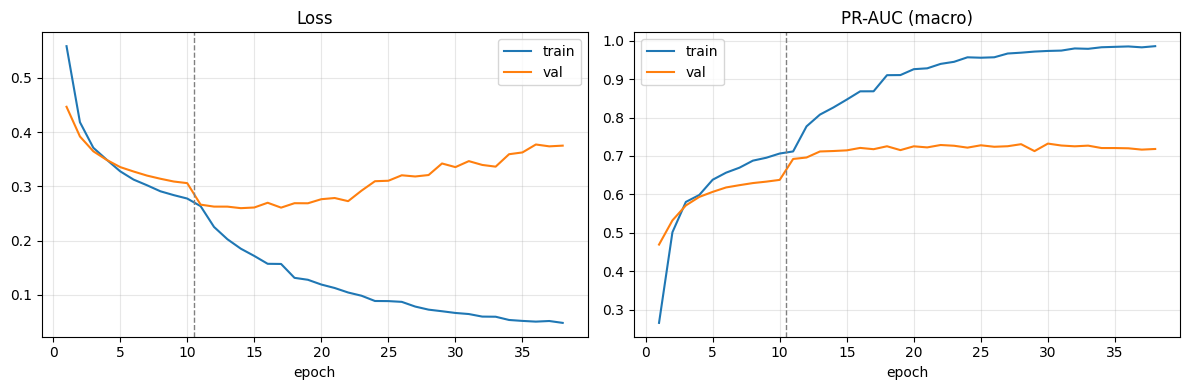

training_results.json complete


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import pandas as pd
import json
import matplotlib.pyplot as plt
from google.colab import files

history = pd.read_csv(f"{FINAL_DIR}/training.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["epoch"] + 1, history["loss"], label="train")
ax[0].plot(history["epoch"] + 1, history["val_loss"], label="val")
ax[0].set_title("Loss")
ax[1].plot(history["epoch"] + 1, history["PR_AUC"], label="train")
ax[1].plot(history["epoch"] + 1, history["val_PR_AUC"], label="val")
ax[1].set_title("PR-AUC (macro)")
for a in ax:
    a.axvline(EPOCHS_HEAD + 0.5, ls="--", c="grey", lw=1)   # เส้นแบ่งช่วง fine-tune
    a.set_xlabel("epoch")
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FINAL_DIR}/training_curves.png", dpi=150)
plt.show()

training_results = {
    "loss": history["loss"].tolist(),
    "val_loss": history["val_loss"].tolist(),
    "pr_auc": history["PR_AUC"].tolist(),
    "val_pr_auc": history["val_PR_AUC"].tolist()
}
metrics_path = f"{FINAL_DIR}/training_results.json"
with open(metrics_path, "w") as file:
    json.dump(training_results, file, indent=2)
print("training_results.json complete")

files.download(metrics_path)
files.download(f"{FINAL_DIR}/training_curves.png")
files.download(f"{FINAL_DIR}/test_per_class.csv")

In [10]:
from pathlib import Path
import tensorflow as tf

needed_files = ["model.keras", "classes.json", "thresholds.json", "config.json"]

for file_name in needed_files:
    file_path = Path(FINAL_DIR) / file_name

    if file_path.exists():
        size = file_path.stat().st_size / 1e6
        print(f"{file_name}: {size:.1f} MB")
    else:
        print(f"{file_name}: ไม่พบ")

print("TensorFlow version:", tf.__version__)

model.keras: 17.2 MB
classes.json: 0.0 MB
thresholds.json: 0.0 MB
config.json: 0.0 MB
TensorFlow version: 2.21.0


In [19]:
import json
import pandas as pd
import tensorflow as tf
import keras
from pathlib import Path
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score

RUN = Path(FINAL_DIR)

model = keras.models.load_model(RUN / "model.keras", compile = False)

classes = json.load(open(Path(DATA_DIR)/"classes.json", encoding="utf-8"))
data = pd.read_csv(Path(DATA_DIR) / "dataset.csv")

def load_images(paths):
  def load_image(path):
    image = tf.io.decode_jpeg(
        tf.io.read_file(path),
        channels=3
    )

    image = tf.image.resize(
        tf.cast(image, tf.float32),
        (IMG_SIZE, IMG_SIZE)
    )

    return image

  dataset = tf.data.Dataset.from_tensor_slices(paths)
  dataset = dataset.map(load_image)

  return dataset.batch(32)

def get_data(split_name):
  data_split = data[data["split"] == split_name].reset_index(drop=True)

  paths = [
      str(Path(DATA_DIR)/path)
      for path in data_split["cache_path"]
  ]

  labels = data_split[classes].values.astype(int)

  return data_split, paths, labels

train_data, train_paths, train_labels = get_data("train")
val_data, val_paths, val_labels = get_data("val")
test_data, test_paths, test_labels = get_data("test")

val_predictions = model.predict(load_images(val_paths), verbose = 0)
test_predictions = model.predict(load_images(test_paths), verbose = 0)

print(
    f"val_predictions.shape: {val_predictions.shape}",
    f"test_predictions.shape: {test_predictions.shape}",
    f"classes: {len(classes)}"
)


val_predictions.shape: (444, 33) test_predictions.shape: (439, 33) classes: 33


In [20]:
!cp "{FINAL_DIR}/fusion_comparison.csv" "{FINAL_DIR}/fusion_comparison_variant.csv"
!cp "{FINAL_DIR}/allergen_thresholds_test.csv" "{FINAL_DIR}/allergen_thresholds_test_variant.csv"

In [21]:
# สูตรเฉลี่ย = สัดส่วนรูปใน train ของเมนูนั้นที่มีส่วนผสมแต่ละตัว
# ผลรวม = W × โมเดลภาพ + (1 − W) × สูตรเฉลี่ย   (เลือก W และ threshold จาก val เท่านั้น)
DISH_TO_MODEL = {
    "pad thai": "padthai",
    "tom yum": "tomyum",
    "larb": "larb",
    "green curry": "greencurry",
    "thaisourcurry": "thaisourcurry",
    "massamancurry": "massamancurry",
    "pad kra pao": "padkrapao",
    "pad kra pao crispy pork": "padkrapao",
    "som tum": "somtam",
    "panang": "panangchickencurry",
    "tomkha": "tomkhagai",
}
for data in (train_data, val_data, test_data):
    data["dish_model"] = data["dish"].map(DISH_TO_MODEL)
    assert data["dish_model"].notna().all(), data.loc[data["dish_model"].isna(), "dish"].unique()

PRIOR_LEVEL = "dish_model"

prior_table = train_data.groupby(PRIOR_LEVEL)[classes].mean()
global_mean = train_data[classes].mean().values

def get_prior(data):
    return np.array([
        prior_table.loc[variant].values
        if variant in prior_table.index
        else global_mean
        for variant in data[PRIOR_LEVEL]
    ])

prior_val = get_prior(val_data)
prior_test = get_prior(test_data)

threshold_grid = np.arange(0.05, 0.96, 0.05)

def get_threshold(labels, predictions):
    thresholds = np.full(labels.shape[1], 0.5)

    for index in range(labels.shape[1]):
        if labels[:, index].sum() >= 3:
            f1_scores = [
                f1_score(
                    labels[:, index],
                    predictions[:, index] >= threshold,
                    zero_division=0
                )
                for threshold in threshold_grid
            ]

            thresholds[index] = threshold_grid[np.argmax(f1_scores)]

    return thresholds

def get_scores(labels, predictions, thresholds):
    predicted_labels = (predictions >= thresholds).astype(int)
    valid_classes = labels.sum(axis=0) > 0

    return {
        "macro_F1": f1_score(
            labels[:, valid_classes],
            predicted_labels[:, valid_classes],
            average="macro",
            zero_division=0
        ),
        "micro_F1": f1_score(
            labels,
            predicted_labels,
            average="micro",
            zero_division=0
        ),
        "mAP": np.mean([
            average_precision_score(labels[:, index], predictions[:, index])
            for index in range(labels.shape[1])
            if labels[:, index].sum() > 0
        ])
    }

weight_results = []

for image_weight in np.arange(0, 1.1, 0.1):
    fused_predictions = (
        image_weight * val_predictions
        + (1 - image_weight) * prior_val
    )

    thresholds = get_threshold(val_labels, fused_predictions)
    macro_f1 = get_scores(
        val_labels,
        fused_predictions,
        thresholds
    )["macro_F1"]

    weight_results.append((image_weight, macro_f1))

W = max(weight_results, key=lambda x: x[1])[0]

print("val macro-F1:")

for image_weight, macro_f1 in weight_results:
    print(f"W={image_weight:.1f}: {macro_f1:.3f}")

print(f"\nเลือก W = {W}")

fused_val = W * val_predictions + (1 - W) * prior_val
fused_test = W * test_predictions + (1 - W) * prior_test

threshold_image = get_threshold(val_labels, val_predictions)
threshold_prior = get_threshold(val_labels, prior_val)
threshold_fused = get_threshold(val_labels, fused_val)

comparison = pd.DataFrame({
    "โมเดลภาพอย่างเดียว": get_scores(
        test_labels,
        test_predictions,
        threshold_image
    ),
    "สูตรเฉลี่ยของเมนูอย่างเดียว": get_scores(
        test_labels,
        prior_test,
        threshold_prior
    ),
    f"รวมกัน (W={W})": get_scores(
        test_labels,
        fused_test,
        threshold_fused
    )
}).T.round(3)

comparison.to_csv(RUN / "fusion_comparison.csv")
display(comparison)

val macro-F1:
W=0.0: 0.617
W=0.1: 0.718
W=0.2: 0.737
W=0.3: 0.742
W=0.4: 0.744
W=0.5: 0.743
W=0.6: 0.739
W=0.7: 0.737
W=0.8: 0.729
W=0.9: 0.724
W=1.0: 0.721

เลือก W = 0.4


,macro_F1,micro_F1,mAP
โมเดลภาพอย่างเดียว,0.670,0.758,0.735
สูตรเฉลี่ยของเมนูอย่างเดียว,0.651,0.691,0.579
รวมกัน (W=0.4),0.705,0.801,0.773


In [22]:
# สารก่อภูมิแพ้: เลือก threshold สูงสุดบน val ที่ยังได้ recall ≥ TARGET_RECALL (ไม่สูงกว่า threshold แบบ F1)
ALLERGENS = ["shrimp", "egg", "peanut", "fish", "squid", "mussel", "salted_crab"]
TARGET_RECALL = 0.90

final_thresholds = threshold_fused.copy()

for ingredient in ALLERGENS:
    if ingredient not in classes:
        continue

    index = classes.index(ingredient)

    valid_thresholds = [
        threshold
        for threshold in np.arange(0.02, 0.96, 0.01)
        if recall_score(
            val_labels[:, index],
            fused_val[:, index] >= threshold,
            zero_division=0
        ) >= TARGET_RECALL
    ]

    if valid_thresholds:
        final_thresholds[index] = min(
            threshold_fused[index],
            max(valid_thresholds)
        )
    else:
        final_thresholds[index] = 0.02


results = []

for ingredient in ALLERGENS:
    if ingredient not in classes:
        continue

    index = classes.index(ingredient)
    true_labels = test_labels[:, index]
    predictions = fused_test[:, index]

    results.append({
        "ingredient": ingredient,
        "n_test": int(true_labels.sum()),
        "thr_F1": round(threshold_fused[index], 2),
        "P_F1": precision_score(true_labels, predictions >= threshold_fused[index], zero_division=0),
        "R_F1": recall_score(true_labels, predictions >= threshold_fused[index], zero_division=0),
        "thr_recall": round(final_thresholds[index], 2),
        "P_recall": precision_score(true_labels, predictions >= final_thresholds[index], zero_division=0),
        "R_recall": recall_score(true_labels, predictions >= final_thresholds[index], zero_division=0)
    })

allergen_table = pd.DataFrame(results).round(3)

allergen_table.to_csv(
    RUN / "allergen_thresholds_test.csv",
    index=False
)

display(allergen_table)

system_scores = get_scores(
    test_labels,
    fused_test,
    final_thresholds
)

print(
    "\nทั้งระบบ (รวมโมเดล + threshold เน้น recall):",
    {key: round(value, 3) for key, value in system_scores.items()}
)

fusion_data = {
    "weight_image": float(W),
    "prior_level": PRIOR_LEVEL,
    "prior": {
        key: dict(zip(classes, map(float, value)))
        for key, value in prior_table.iterrows()
    },
    "default_prior": dict(zip(classes, map(float, global_mean)))
}

with open(RUN / "fusion.json", "w", encoding="utf-8") as file:
    json.dump(fusion_data, file, indent=2, ensure_ascii=False)

with open(RUN / "thresholds_fused.json", "w", encoding="utf-8") as file:
    json.dump(
        dict(zip(classes, map(float, final_thresholds))),
        file,
        indent=2
    )

print("บันทึก fusion.json, thresholds_fused.json ใน", RUN)

,ingredient,n_test,thr_F1,P_F1,R_F1,thr_recall,P_recall,R_recall
0,shrimp,111,0.60,0.880,0.928,0.60,0.880,0.928
1,egg,31,0.40,0.833,0.645,0.20,0.452,0.903
2,peanut,48,0.20,0.818,0.938,0.20,0.818,0.938
3,fish,33,0.25,0.818,0.818,0.15,0.400,0.970
4,squid,17,0.40,0.692,0.529,0.16,0.258,1.000
5,mussel,14,0.25,0.611,0.786,0.14,0.400,0.857
6,salted_crab,11,0.35,0.875,0.636,0.35,0.875,0.636



ทั้งระบบ (รวมโมเดล + threshold เน้น recall): {'macro_F1': 0.684, 'micro_F1': 0.781, 'mAP': np.float64(0.773)}
บันทึก fusion.json, thresholds_fused.json ใน /content/drive/MyDrive/Colab Notebooks/ingredient_model/runs/model_final
